## Raster data manipulation with GDAL and RIOXARRAY

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray as rxr

In [40]:
# !ls ../PS_DS_data/track_81

# GDAL

GDAL (Geospatial Data Abstraction Library) is a free and open-source software library that supports more than 80 raster image formats and map projections. It provides command-line tools and APIs for C/C++, Python, and R, making it widely used by major geospatial data services worldwide. GDAL also offers an extensive test suite and an active developer community, ensuring its reliability and continued development. In addition to raster data, GDAL provides comprehensive support for vector datasets, which are beyond the scope of this tutorial.


## GDAL Command Line Utilities

* **`gdalinfo`**: Displays detailed information about a raster dataset (e.g., dimensions, coordinates, projection, and band metadata).
* **`gdalsrsinfo`**: Outputs the Spatial Reference System (SRS) of a dataset, demonstrating the structure and complexities involved in supporting various coordinate systems.
* **`gdal_translate`**: Used for raster conversions and data manipulation, such as changing file formats, extracting single bands, assigning NoData values, cropping, or oversampling/regridding.
* **`gdalwarp`**: An advanced image mosaicing, reprojection, and warping utility. It can be used as a standalone executable or programmatically to handle complex coordinate transformations, cropping, and grid manipulations.
* **`gdaltransform`**: Transforms specific coordinate pairs (X, Y) from one coordinate reference system (CRS) or pixel/line grid space to another.


In [80]:
from osgeo import gdal, osr

In [45]:
# file_path = "../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif"

In [44]:
!gdalinfo ../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif

Driver: GTiff/GeoTIFF
Files: ../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif
       ../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif.aux.xml
Size is 4072, 3258
Coordinate System is:
GEOGCRS["WGS 84",
    ENSEMBLE["World Geodetic System 1984 ensemble",
        MEMBER["World Geodetic System 1984 (Transit)"],
        MEMBER["World Geodetic System 1984 (G730)"],
        MEMBER["World Geodetic System 1984 (G873)"],
        MEMBER["World Geodetic System 1984 (G1150)"],
        MEMBER["World Geodetic System 1984 (G1674)"],
        MEMBER["World Geodetic System 1984 (G1762)"],
        MEMBER["World Geodetic System 1984 (G2139)"],
        MEMBER["World Geodetic System 1984 (G2296)"],
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]],
        ENSEMBLEACCURACY[2.0]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            A

In [74]:
# !gdalinfo -stats ../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif

In [66]:
###How do we get this information programatically
ds = gdal.Open(file_path, gdal.GA_ReadOnly)
band = ds.GetRasterBand(1)
print('Bands = ', ds.RasterCount)
print('Dimensions = ', ds.RasterXSize, ' x ', ds.RasterYSize)
print('Data type:', gdal.GetDataTypeName(band.DataType))
print('NoData value:', band.GetNoDataValue())

ds = None

Bands =  1
Dimensions =  4072  x  3258
Data type: Float32
NoData value: None


In [48]:
##Get projection information for a raster file
!gdalsrsinfo -o proj4  ../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif


+proj=longlat +datum=WGS84 +no_defs



In [49]:
###Programmatic method of querying spatial reference
ds = gdal.Open(file_path, gdal.GA_ReadOnly)
srs = ds.GetProjectionRef()
ds = None
print(srs)

ref = osr.SpatialReference()
ref.ImportFromWkt(srs)
ref.ExportToProj4()

GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]


'+proj=longlat +datum=WGS84 +no_defs'

### Coordinates on a map


GDAL uses a simple affine system to translate (pixel, line) location to (X,Y) coordinates in map coordinates. The affine system is represented by 6 double precision numbers collectively known as the ''GeoTransform''.

```
[TopLeft_X, Pixel_Width_X, Row_Rotation_X, TopLeft_Y, Column Rotation_Y, -Pixel_Height_Y]
```
**Top-left** map coordinate of a pixel represented by pixel number (P) and line number (L) in C/Python indexing is given by

$$\begin{equation*}
\left[ \begin{array}{c}
X_{left} \\
Y_{top}
\end{array} \right] = \left[ \begin{array}{c}
G_0 \\
G_3 \end{array}\right] + \left[ \begin{array}{cc}
G_1 & G_2 \\
G_4 & G_5 
\end{array} \right] \cdot \left[ \begin{array}{c}
P \\
L 
\end{array} \right]
\end{equation*}
$$


Here is the exact manner in which pixel indices are interpreted by GDAL
![Raster Layout](Raster_layout.png)

In [50]:
###Programmatic method of querying the geotransform

ds = gdal.Open(file_path, gdal.GA_ReadOnly)
print(ds.GetGeoTransform())
ds = None

(-1.9084799881468595, 0.00035993385761910366, 0.0, 45.14004473270436, 0.0, -0.00035993385761910366)


In [129]:
###The usual python imports for the notebook

gdal.UseExceptions()

#Utility function to load data
def loadData(infile, band=1):
    ds = gdal.Open(infile, gdal.GA_ReadOnly)
    band = ds.GetRasterBand(band)
    arr = band.ReadAsArray()
    #Map extent
    trans = ds.GetGeoTransform()
    xsize = ds.RasterXSize
    ysize = ds.RasterYSize
    extent = [trans[0], trans[0] + xsize * trans[1],
            trans[3] + ysize*trans[5], trans[3]]
    
    ds = None
    return arr, extent

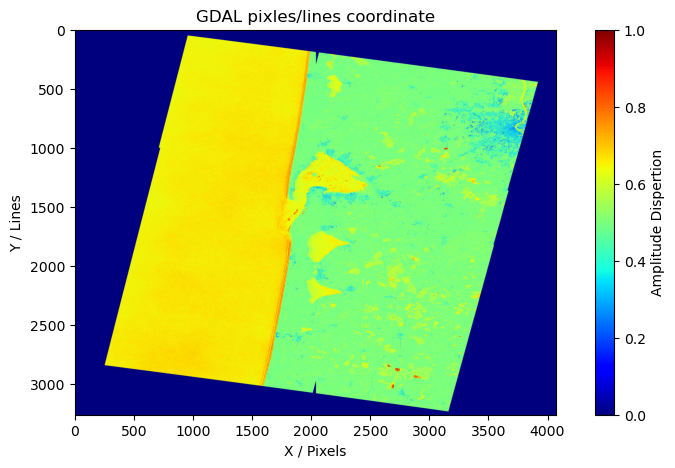

In [130]:
tif, tifext = loadData(file_path)

f, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(tif, 
               clim=[0, 1],     
               # extent=tifext, 
               cmap='jet')
ax.set(xlabel="X / Pixels",      
       ylabel="Y / Lines",
       title="GDAL pixles/lines coordinate")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Amplitude Dispertion')  

plt.show()

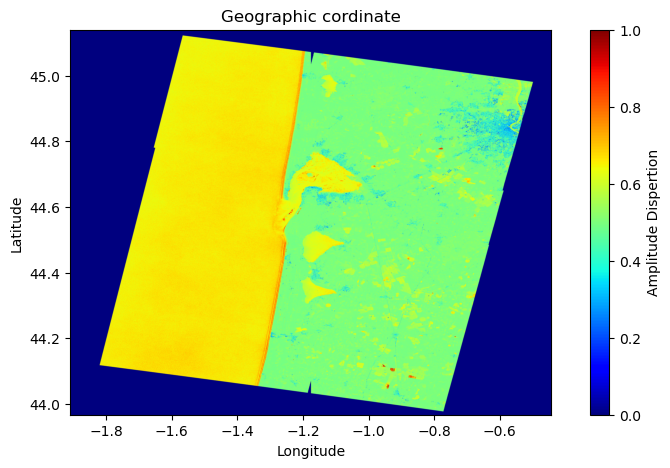

In [131]:
tif, tifext = loadData(file_path)

f, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(tif, 
               clim=[0, 1],     
               extent=tifext, 
               cmap='jet')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Amplitude Dispertion')  

ax.set(xlabel="Longitude",      
       ylabel="Latitude",
       title="Geographic cordinate")

plt.show()

## Handling NoData Values and Mask Values

**Sometimes there are raster values that are 0 for mask, we need to also remove them**

```python
# Open raster in update mode (1 = GA_Update)
ds = gdal.Open("your_raster.tif", 1)
band = ds.GetRasterBand(1)
arr = band.ReadAsArray()
nodata_value = -9999    ## can you another value
arr = np.where(arr == 0, nodata_value, arr)
band.WriteArray(arr)
band.SetNoDataValue(new_value)
band.FlushCache()
ds = None
```

or


```python
arr[arr == 0] = np.nan
```

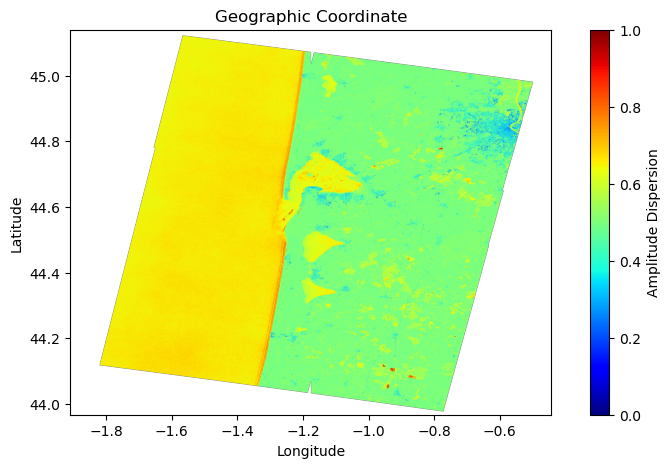

In [134]:
nodata = -9999
tif = np.where(tif == 0, nodata, tif)  # change 0 to -9999

masked_tif = np.ma.masked_equal(tif, nodata) # Create a masked array where -9999 values are hidden

f, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(masked_tif, 
               clim=[0, 1],     
               extent=tifext, 
               cmap='jet')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Amplitude Dispersion')

ax.set(xlabel="Longitude",      
       ylabel="Latitude",
       title="Geographic Coordinate")

plt.show()

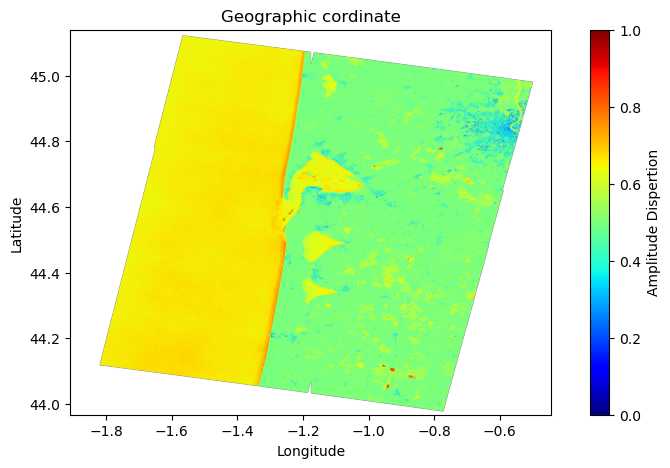

In [135]:
tif[tif==-9999] = np.nan 

f, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(tif, 
               clim=[0, 1],     
               extent=tifext, 
               cmap='jet')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Amplitude Dispertion')  

ax.set(xlabel="Longitude",      
       ylabel="Latitude",
       title="Geographic cordinate")

plt.show()

# rioxarray

rioxarray is a free and open-source Python library that extends xarray to support geospatial raster data. It combines xarray's powerful handling of multidimensional arrays with rasterio's geospatial capabilities, allowing users to read, process, analyze, and write raster datasets while preserving spatial information such as coordinate reference systems (CRS), georeferencing, and spatial resolution. It integrates seamlessly with NumPy, pandas, and other scientific Python libraries, making it particularly useful for analyzing satellite imagery, digital elevation models, and InSAR products. With its intuitive interface and support for labeled multidimensional data, rioxarray simplifies geospatial workflows and is especially useful for working with large raster datasets in Python.

In [82]:
file_path = "../PS_DS_data/track_81/amp_dispersion_looked_geocoded.tif"

df = rxr.open_rasterio(file_path)

In [83]:
df

<xarray.DataArray (band: 1, y: 3258, x: 4072)> Size: 53MB
[13266576 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 26kB 45.14 45.14 45.14 45.14 ... 43.97 43.97 43.97
  * x            (x) float64 33kB -1.908 -1.908 -1.908 ... -0.4434 -0.443
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:             Area
    STATISTICS_MAXIMUM:        2.470703125
    STATISTICS_MEAN:           0.36311502774606
    STATISTICS_MINIMUM:        0
    STATISTICS_STDDEV:         0.28258678357733
    STATISTICS_VALID_PERCENT:  100
    scale_factor:              1.0
    add_offset:                0.0

In [136]:
# View generate metadata associated with the raster file
print("The crs of your data is:", df.rio.crs)
print("The nodatavalue of your data is:", df.rio.nodata)
print("The spatial extent is:", df.rio.bounds())
print("The spatial resolution for your data is:", df.rio.resolution())
print("The shape of your data is:", df.shape)
print("The metadata for your data is:", df.attrs)

The crs of your data is: EPSG:4326
The nodatavalue of your data is: None
The spatial extent is: (-1.9084799881468595, 43.96738022458132, -0.4428293199218694, 45.14004473270436)
The spatial resolution for your data is: (0.00035993385761910366, -0.00035993385761910366)
The shape of your data is: (3258, 4072)
The metadata for your data is: {'AREA_OR_POINT': 'Area', 'STATISTICS_MAXIMUM': 2.470703125, 'STATISTICS_MEAN': 0.36311502774606, 'STATISTICS_MINIMUM': 0, 'STATISTICS_STDDEV': 0.28258678357733, 'STATISTICS_VALID_PERCENT': 100, 'scale_factor': 1.0, 'add_offset': 0.0}


In [89]:
df.coords  # Coordinates (e.g., y, x in geographic or projected CRS)

Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 26kB 45.14 45.14 45.14 45.14 ... 43.97 43.97 43.97
  * x            (x) float64 33kB -1.908 -1.908 -1.908 ... -0.4434 -0.443
    spatial_ref  int64 8B 0

In [87]:
# View the structure of the DataArray
df.dims  # Dimensions (e.g., band, y, x)

('band', 'y', 'x')

In [85]:
# Notice that the shape of this object has a 1 at the beginning
# This can cause issues with plotting
df.shape

(1, 3258, 4072)

In [95]:
# Open the data and mask no data values
# Squeeze reduces the third dimension given there is only one "band" or layer to this data
df = rxr.open_rasterio(file_path, masked=True).squeeze()
# Notice there are now only 2 dimensions to your array
df.shape

(3258, 4072)

In [86]:
print("the minimum raster value is: ", np.nanmin(df.values))
print("the maximum raster value is: ", np.nanmax(df.values))

the minimum raster value is:  0.0
the maximum raster value is:  2.4707031


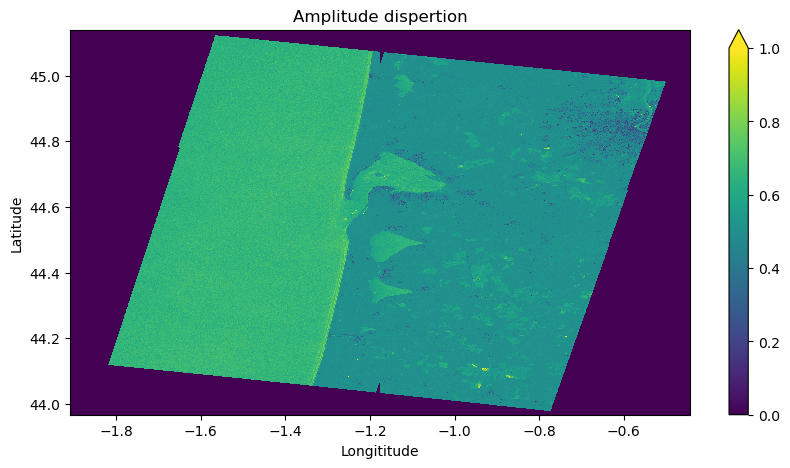

In [137]:
## rioxaary default plot 

# Plot the data and notice that the scale bar looks better
# No data values are now masked
f, ax = plt.subplots(figsize=(10, 5))
df.plot(ax=ax,vmin=0,vmax=1)
ax.set(title="Amplitude dispertion",
      xlabel="Longititude",
      ylabel="Latitude",
    )
# ax.set_axis_off()
plt.show()

In [139]:
# Check the affine transformation (mapping pixel coordinates to geographic coordinates)
df.rio.transform()

Affine(0.00035993385761910366, 0.0, -1.9084799881468595,
       0.0, -0.00035993385761910366, 45.14004473270436)

In [140]:
## getting the map extent

## 1st
trans = df.rio.transform()
xsize = df.rio.width
ysize = df.rio.height

extent = [trans[2], trans[2] + xsize * trans[0],
        trans[5] + ysize*trans[4], trans[5]]

## 2nd

left, bottom, right, top = df.rio.bounds()   # Get the bounds from rioxarray
img_extent = [left, right, bottom, top]      # 2. Reorder for matplotlib imshow format: [xmin, xmax, ymin, ymax]

In [142]:
extent

[-1.9084799881468595,
 -0.44282931992186936,
 43.96738022458132,
 45.14004473270436]

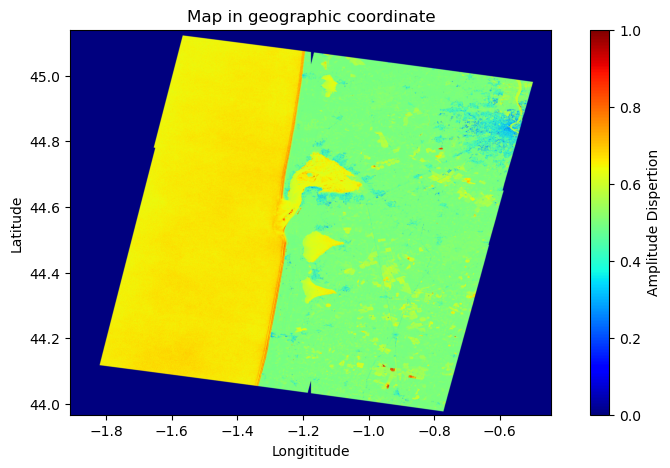

In [143]:
## Plot with extent

f, ax = plt.subplots(figsize=(10,5))

im = ax.imshow(df, clim=[0,1], 
          extent=img_extent, 
          cmap='jet')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Amplitude Dispertion') 

ax.set(xlabel = "Longititude",
      ylabel = "Latitude",
      title = "Map in geographic coordinate")

plt.show()

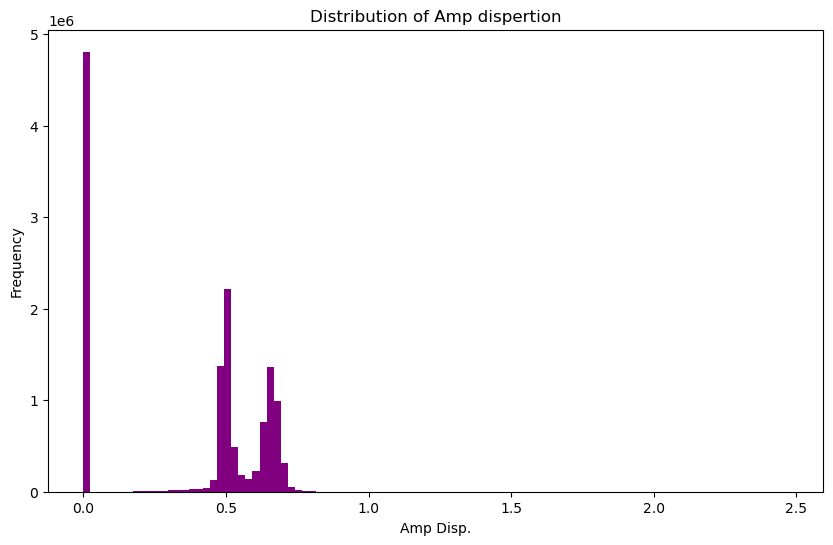

In [152]:
f, ax = plt.subplots(figsize=(10, 6))
df.plot.hist(color="purple",
            # bins=[0, 0.2, 0.4, 0.6, 0.8, 1],
            bins=100,
            )
ax.set(title="Distribution of Amp dispertion",
       xlabel='Amp Disp.',
       ylabel='Frequency')
plt.show()

## Handling 0 Values

**Sometimes there are raster values that are 0 for mask, we need to also remove them**
```python
df_masked = df.where(df != 0)    ## for xarray type data
```

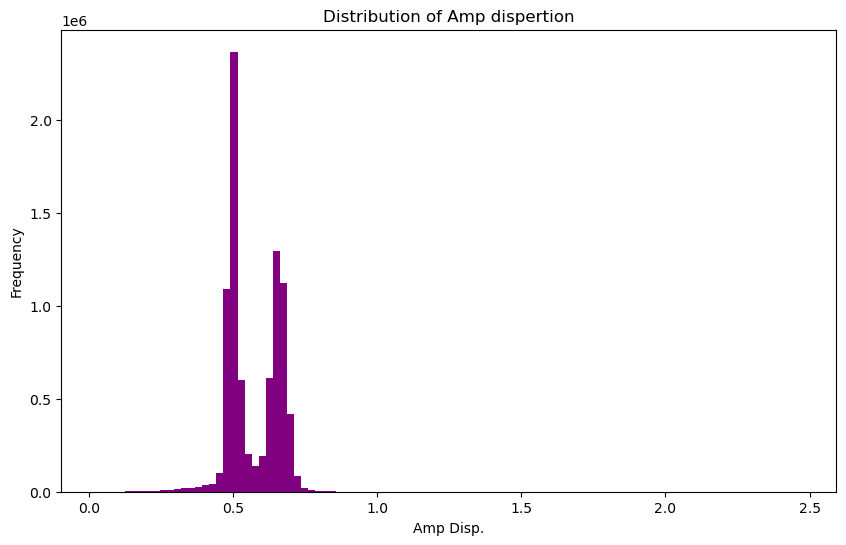

In [153]:
df_masked = df.where(df != 0) 

f, ax = plt.subplots(figsize=(10, 6))
df_masked.plot.hist(color="purple",
                    # bins=[0, 0.2, 0.4, 0.6, 0.8, 1],
                    bins=100,
                   )
ax.set(title="Distribution of Amp dispertion",
       xlabel='Amp Disp.',
       ylabel='Frequency')
plt.show()

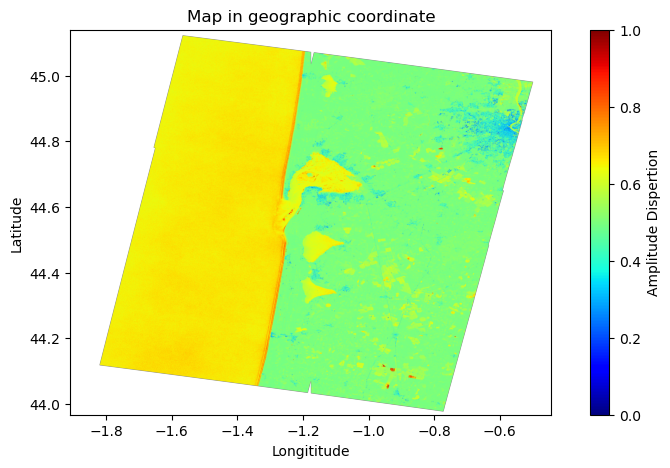

In [150]:
## Plot with extent

f, ax = plt.subplots(figsize=(10,5))

im = ax.imshow(df_masked, clim=[0,1], 
          extent=img_extent, 
          cmap='jet')

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Amplitude Dispertion') 

ax.set(xlabel = "Longititude",
      ylabel = "Latitude",
      title = "Map in geographic coordinate")

plt.show()